# 多项式回归

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression # 线性模型
from sklearn.tree import DecisionTreeRegressor # 非线性模型

/opt/anaconda3/lib/python3.9/site-packages/scipy/__init__.py:132: UserWarning: A NumPy version >=1.21.6 and <1.28.0 is required for this version of SciPy (detected version 1.21.5)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
rnd = np.random.RandomState(42) # 设置随机数种子
X = rnd.uniform(-3, 3, size=100) # random.uniform，从输入的任意两个整数中取出size个随机数

In [3]:
X #作为横坐标

array([-0.75275929,  2.70428584,  1.39196365,  0.59195091, -2.06388816,
       -2.06403288, -2.65149833,  2.19705687,  0.60669007,  1.24843547,
       -2.87649303,  2.81945911,  1.99465584, -1.72596534, -1.9090502 ,
       -1.89957294, -1.17454654,  0.14853859, -0.40832989, -1.25262516,
        0.67111737, -2.16303684, -1.24713211, -0.80182894, -0.26358009,
        1.71105577, -1.80195731,  0.08540663,  0.55448741, -2.72129752,
        0.64526911, -1.97685526, -2.60969044,  2.69331322,  2.7937922 ,
        1.85038409, -1.17231738, -2.41396732,  1.10539816, -0.35908504,
       -2.26777059, -0.02893854, -2.79366887,  2.45592241, -1.44732011,
        0.97513371, -1.12973354,  0.12040813,  0.28026168, -1.89087327,
        2.81750777,  1.65079694,  2.63699365,  2.3689641 ,  0.58739987,
        2.53124541, -2.46904499, -1.82410283, -2.72863627, -1.04801802,
       -0.66793626, -1.37190581,  1.97242505, -0.85948004, -1.31439294,
        0.2561765 , -2.15445465,  1.81318188, -2.55269614,  2.92

In [4]:
# 噪音
rnd.normal(size=100)

array([ 0.08704707, -0.29900735,  0.09176078, -1.98756891, -0.21967189,
        0.35711257,  1.47789404, -0.51827022, -0.8084936 , -0.50175704,
        0.91540212,  0.32875111, -0.5297602 ,  0.51326743,  0.09707755,
        0.96864499, -0.70205309, -0.32766215, -0.39210815, -1.46351495,
        0.29612028,  0.26105527,  0.00511346, -0.23458713, -1.41537074,
       -0.42064532, -0.34271452, -0.80227727, -0.16128571,  0.40405086,
        1.8861859 ,  0.17457781,  0.25755039, -0.07444592, -1.91877122,
       -0.02651388,  0.06023021,  2.46324211, -0.19236096,  0.30154734,
       -0.03471177, -1.16867804,  1.14282281,  0.75193303,  0.79103195,
       -0.90938745,  1.40279431, -1.40185106,  0.58685709,  2.19045563,
       -0.99053633, -0.56629773,  0.09965137, -0.50347565, -1.55066343,
        0.06856297, -1.06230371,  0.47359243, -0.91942423,  1.54993441,
       -0.78325329, -0.32206152,  0.81351722, -1.23086432,  0.22745993,
        1.30714275, -1.60748323,  0.18463386,  0.25988279,  0.78

In [5]:
# 生成y的思路：先使用NumPy中的函数生成一个sin函数图像，然后再人为添加噪音
y = np.sin(X) + rnd.normal(size=len(X)) / 3 # random.normal，生成size个服从正态分布的随机数

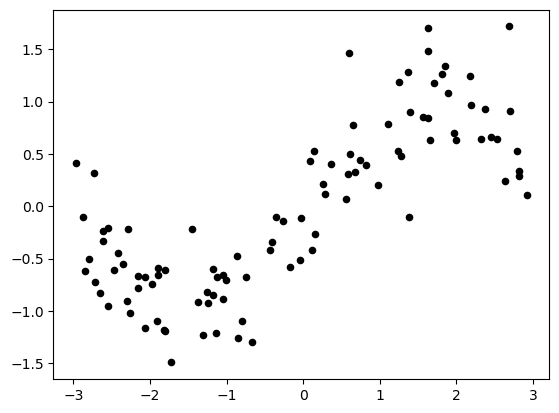

In [6]:
# 使用散点图观察建立的数据集是什么样子
plt.scatter(X, y, marker='o', c='k', s=20)
plt.show()

In [7]:
# 为后续建模做准备：sklearn只接受二维以上数组作为特征矩阵的输入
X.shape

(100,)

In [8]:
X = X.reshape(-1, 1)

In [10]:
X.shape

(100, 1)

In [11]:
X

array([[-0.75275929],
       [ 2.70428584],
       [ 1.39196365],
       [ 0.59195091],
       [-2.06388816],
       [-2.06403288],
       [-2.65149833],
       [ 2.19705687],
       [ 0.60669007],
       [ 1.24843547],
       [-2.87649303],
       [ 2.81945911],
       [ 1.99465584],
       [-1.72596534],
       [-1.9090502 ],
       [-1.89957294],
       [-1.17454654],
       [ 0.14853859],
       [-0.40832989],
       [-1.25262516],
       [ 0.67111737],
       [-2.16303684],
       [-1.24713211],
       [-0.80182894],
       [-0.26358009],
       [ 1.71105577],
       [-1.80195731],
       [ 0.08540663],
       [ 0.55448741],
       [-2.72129752],
       [ 0.64526911],
       [-1.97685526],
       [-2.60969044],
       [ 2.69331322],
       [ 2.7937922 ],
       [ 1.85038409],
       [-1.17231738],
       [-2.41396732],
       [ 1.10539816],
       [-0.35908504],
       [-2.26777059],
       [-0.02893854],
       [-2.79366887],
       [ 2.45592241],
       [-1.44732011],
       [ 0

In [12]:
# 使用原始数据进行建模
LinearR = LinearRegression().fit(X, y)
TreeR = DecisionTreeRegressor(random_state=0).fit(X, y)

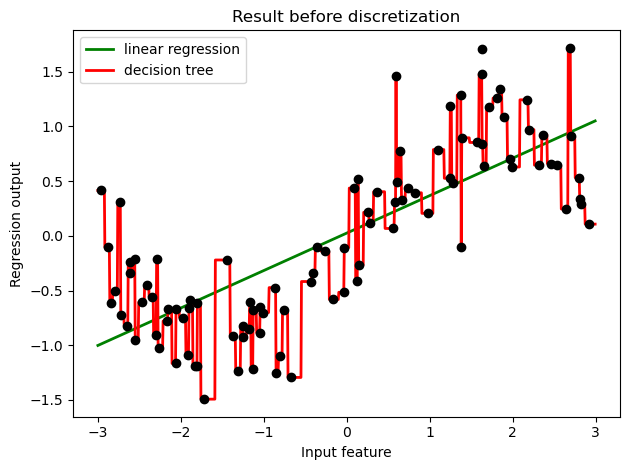

In [18]:
# 放置画布
fig, ax1 = plt.subplots(1)

# 创建测试数据：一系列分布在横坐标上的点
line = np.linspace(-3, 3, 1000, endpoint=False).reshape(-1, 1)

# 将测试数据带入predict接口，获得模型的拟合效果并进行绘制
ax1.plot(line, LinearR.predict(line), linewidth=2, color='green',
         label="linear regression")
ax1.plot(line, TreeR.predict(line), linewidth=2, color='red',
         label="decision tree")

# 将原数据绘制在图像上
ax1.plot(X[:, 0], y, 'o', c='k')

# 其他图形选项
ax1.legend(loc="best")
ax1.set_ylabel("Regression output")
ax1.set_xlabel("Input feature")
ax1.set_title("Result before discretization")
plt.tight_layout()
plt.show()

In [19]:
# 使用分箱处理非线性问题

from sklearn.preprocessing import KBinsDiscretizer

# 将数据分箱
enc = KBinsDiscretizer(n_bins=10 #分10类
                       , encode="onehot") #ordinal
X_binned = enc.fit_transform(X)
# encode模式"onehot"：使用做哑变量方式做离散化
# 之后返回一个稀疏矩阵(m,n_bins)，每一列是一个分好的类别
# 对每一个样本而言，它包含的分类（箱子）中它表示为1，其余分类中它表示为0

In [26]:
X

array([[-0.75275929],
       [ 2.70428584],
       [ 1.39196365],
       [ 0.59195091],
       [-2.06388816],
       [-2.06403288],
       [-2.65149833],
       [ 2.19705687],
       [ 0.60669007],
       [ 1.24843547],
       [-2.87649303],
       [ 2.81945911],
       [ 1.99465584],
       [-1.72596534],
       [-1.9090502 ],
       [-1.89957294],
       [-1.17454654],
       [ 0.14853859],
       [-0.40832989],
       [-1.25262516],
       [ 0.67111737],
       [-2.16303684],
       [-1.24713211],
       [-0.80182894],
       [-0.26358009],
       [ 1.71105577],
       [-1.80195731],
       [ 0.08540663],
       [ 0.55448741],
       [-2.72129752],
       [ 0.64526911],
       [-1.97685526],
       [-2.60969044],
       [ 2.69331322],
       [ 2.7937922 ],
       [ 1.85038409],
       [-1.17231738],
       [-2.41396732],
       [ 1.10539816],
       [-0.35908504],
       [-2.26777059],
       [-0.02893854],
       [-2.79366887],
       [ 2.45592241],
       [-1.44732011],
       [ 0

In [24]:
X_binned

<100x10 sparse matrix of type '<class 'numpy.float64'>'
	with 100 stored elements in Compressed Sparse Row format>

In [25]:
# 使用pandas打开稀疏矩阵
import pandas as pd
pd.DataFrame(X_binned.toarray()).head(10)

,0,1,2,3,4,5,6,7,8,9
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [27]:
# 使用分箱后的数据来训练模型，在sklearn中，测试集和训练集的结构必须保持一致，否则报错
LinearR_ = LinearRegression().fit(X_binned, y)

LinearR_.predict(line) # line作为测试集

ValueError: X has 1 features, but LinearRegression is expecting 10 features as input.

In [28]:
line.shape #测试

(1000, 1)

In [29]:
X_binned.shape #训练

(100, 10)

In [30]:
# 因此需要创建分箱后的测试集：按照已经建好的分箱模型将line分箱
line_binned = enc.transform(line)
line_binned.shape # 分箱后的数据是无法进行绘图的

(1000, 10)

In [31]:
line_binned

<1000x10 sparse matrix of type '<class 'numpy.float64'>'
	with 1000 stored elements in Compressed Sparse Row format>

In [32]:
LinearR_.predict(line_binned).shape

(1000,)

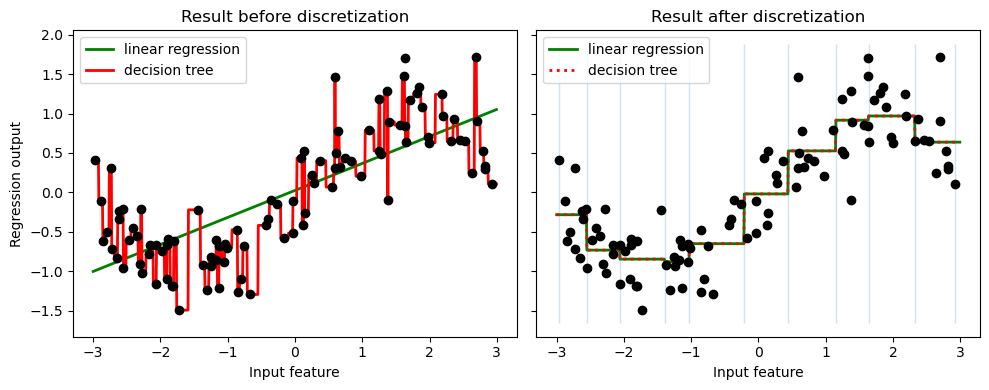

In [33]:
# 准备数据
# X:训练集的X，y:训练集的y，X_binned:训练集分箱以后的X，line:测试集的X，line_binned:测试集分箱以后的X
enc = KBinsDiscretizer(n_bins=10,encode="onehot")
X_binned = enc.fit_transform(X) # 训练集进行分箱以后的X
line_binned = enc.transform(line) # 测试集进行分箱以后的X

# 将两张图像绘制在一起，布置画布
fig, (ax1, ax2) = plt.subplots(ncols=2
                               , sharey=True # 两张图共享y轴上的刻度
                               , figsize=(10, 4))

# 在图1中布置在原始数据上建模的结果
ax1.plot(line, LinearR.predict(line), linewidth=2, color='green',
         label="linear regression")
ax1.plot(line, TreeR.predict(line), linewidth=2, color='red',
         label="decision tree")
ax1.plot(X[:, 0], y, 'o', c='k')
ax1.legend(loc="best")
ax1.set_ylabel("Regression output")
ax1.set_xlabel("Input feature")
ax1.set_title("Result before discretization")

# 使用分箱数据进行建模
LinearR_ = LinearRegression().fit(X_binned, y)
TreeR_ = DecisionTreeRegressor(random_state=0).fit(X_binned, y)

# 进行预测，在图2中布置在分箱数据上进行预测的结果
ax2.plot(line #横坐标
         , LinearR_.predict(line_binned) #分箱后的特征矩阵的结果
         , linewidth=2
         , color='green'
         , linestyle='-'
         , label='linear regression')

ax2.plot(line, TreeR_.predict(line_binned), linewidth=2, color='red',
         linestyle=':', label='decision tree')

# 绘制和箱宽一致的竖线
ax2.vlines(enc.bin_edges_[0] # x轴
           , *plt.gca().get_ylim() # y轴的上限和下限
           , linewidth=1
           , alpha=.2)

# 将原始数据分布放置在图像上
ax2.plot(X[:, 0], y, 'o', c='k')

# 其他绘图设定
ax2.legend(loc="best")
ax2.set_xlabel("Input feature")
ax2.set_title("Result after discretization")
plt.tight_layout()
plt.show()

In [35]:
enc.bin_edges_[0] # 分出的箱子上限和下限

array([-2.9668673 , -2.55299973, -2.0639171 , -1.3945301 , -1.02797432,
       -0.21514527,  0.44239288,  1.14612193,  1.63693428,  2.32784522,
        2.92132162])

0.9421834199226918


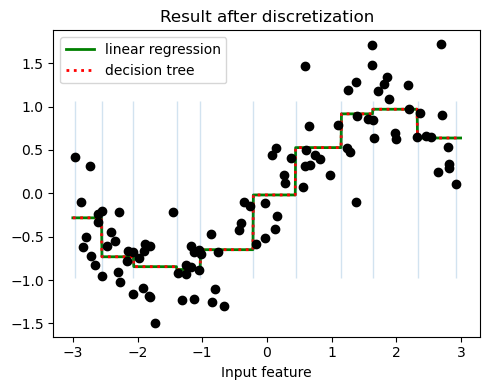

In [40]:
enc = KBinsDiscretizer(n_bins=10, encode="onehot")

X_binned = enc.fit_transform(X)
line_binned = enc.transform(line)

fig, ax2 = plt.subplots(1,figsize=(5,4))

LinearR_ = LinearRegression().fit(X_binned, y)
print(LinearR_.score(line_binned, np.sin(line))) # 输出在测试集上的表现
TreeR_ = DecisionTreeRegressor(random_state=0).fit(X_binned, y)

ax2.plot(line # 横坐标
         , LinearR_.predict(line_binned) # 分箱后的特征矩阵的结果
         , linewidth=2
         , color='green'
         , linestyle='-'
         , label='linear regression')
ax2.plot(line, TreeR_.predict(line_binned), linewidth=2, color='red',
         linestyle=':', label='decision tree')
ax2.vlines(enc.bin_edges_[0], *plt.gca().get_ylim(), linewidth=1, alpha=.2)
ax2.plot(X[:, 0], y, 'o', c='k')
ax2.legend(loc="best")
ax2.set_xlabel("Input feature")
ax2.set_title("Result after discretization")
plt.tight_layout()
plt.show()

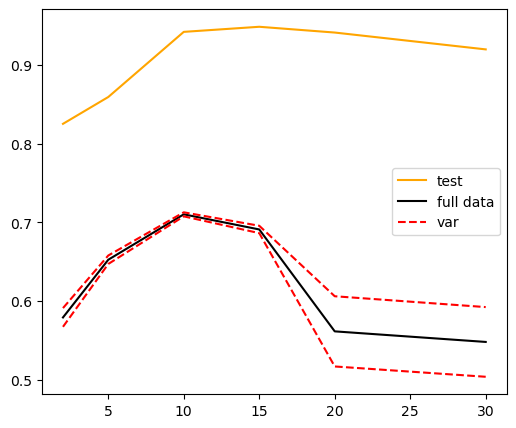

In [41]:
# 如何选取最优的箱数
from sklearn.model_selection import cross_val_score as CVS

pred, score, var = [], [], []
binsrange = [2,5,10,15,20,30]
for i in binsrange:
    # 实例化分箱类
    enc = KBinsDiscretizer(n_bins=i, encode="onehot")
    # 转换数据
    X_binned = enc.fit_transform(X)
    line_binned = enc.transform(line)
    # 建立模型
    LinearR_ = LinearRegression()
    # 全数据集上的交叉验证
    cvresult = CVS(LinearR_, X_binned, y, cv=5)
    score.append(cvresult.mean())
    var.append(cvresult.var())
    # 测试数据集上的打分结果
    pred.append(LinearR_.fit(X_binned,y).score(line_binned, np.sin(line)))
# 绘制图像
plt.figure(figsize=(6,5))
plt.plot(binsrange, pred, c="orange", label="test")
plt.plot(binsrange, score, c="k", label="full data")
plt.plot(binsrange, score+np.array(var)*0.5, c="red", linestyle="--", label = "var")
plt.plot(binsrange, score-np.array(var)*0.5, c="red", linestyle="--")
plt.legend()
plt.show()

In [42]:
# 多项式回归
from sklearn.preprocessing import PolynomialFeatures

In [43]:
# 如果原始数据是一维的
X = np.arange(1,4).reshape(-1,1)
X

array([[1],
       [2],
       [3]])

In [44]:
X.shape

(3, 1)

In [45]:
# 二次多项式，参数degree控制多项式的次方
poly = PolynomialFeatures(degree=2)

In [46]:
# 接口transform直接调用进行转换
X_ = poly.fit_transform(X)

In [47]:
X_

array([[1., 1., 1.],
       [1., 2., 4.],
       [1., 3., 9.]])

In [48]:
X_.shape

(3, 3)

In [49]:
# 三次多项式
PolynomialFeatures(degree=3).fit_transform(X)

array([[ 1.,  1.,  1.,  1.],
       [ 1.,  2.,  4.,  8.],
       [ 1.,  3.,  9., 27.]])

In [50]:
# 三次多项式，不带与截距项相乘的x0
PolynomialFeatures(degree=3, include_bias=False).fit_transform(X)

array([[ 1.,  1.,  1.],
       [ 2.,  4.,  8.],
       [ 3.,  9., 27.]])

In [51]:
# 为什么会希望不生成与截距相乘的x0呢？
# 对于多项式回归来说，已经为线性回归准备好了x0，但是线性回归并不知道
xxx = PolynomialFeatures(degree=3).fit_transform(X)

In [52]:
xxx.shape

(3, 4)

In [53]:
xxx

array([[ 1.,  1.,  1.,  1.],
       [ 1.,  2.,  4.,  8.],
       [ 1.,  3.,  9., 27.]])

In [54]:
rnd = np.random.RandomState(42) # 设置随机数种子
y = rnd.randn(3)

y

array([ 0.49671415, -0.1382643 ,  0.64768854])

In [55]:
# 生成了多少个系数？
LinearRegression().fit(xxx,y).coef_

array([ 2.83453816e-15, -3.51045297e-01, -6.06987134e-01,  2.19575463e-01])

In [56]:
# 查看截距
LinearRegression().fit(xxx,y).intercept_

1.235171120203688

In [57]:
# 发现问题了吗？线性回归并没有把多项式生成的x0当作是截距项
# 所以可以选择：关闭多项式回归中的include_bias
# 也可以选择：关闭线性回归中的fit_intercept

# 生成了多少个系数？
LinearRegression(fit_intercept=False).fit(xxx,y).coef_

array([ 1.00596411,  0.06916756, -0.83619415,  0.25777663])

In [58]:
# 查看截距
LinearRegression(fit_intercept=False).fit(xxx,y).intercept_

0.0

In [59]:
# 尝试二次多项式
X = np.arange(6).reshape(3, 2)
X

array([[0, 1],
       [2, 3],
       [4, 5]])

In [60]:
PolynomialFeatures(degree=2).fit_transform(X)

array([[ 1.,  0.,  1.,  0.,  0.,  1.],
       [ 1.,  2.,  3.,  4.,  6.,  9.],
       [ 1.,  4.,  5., 16., 20., 25.]])

In [61]:
# 尝试三次多项式
PolynomialFeatures(degree=3).fit_transform(X)

array([[  1.,   0.,   1.,   0.,   0.,   1.,   0.,   0.,   0.,   1.],
       [  1.,   2.,   3.,   4.,   6.,   9.,   8.,  12.,  18.,  27.],
       [  1.,   4.,   5.,  16.,  20.,  25.,  64.,  80., 100., 125.]])

In [62]:
PolynomialFeatures(degree=2, interaction_only=True).fit_transform(X)
#对比之下，当interaction_only为True的时候，只生成交互项

array([[ 1.,  0.,  1.,  0.],
       [ 1.,  2.,  3.,  6.],
       [ 1.,  4.,  5., 20.]])

In [63]:
PolynomialFeatures(degree=2).fit_transform(X)

array([[ 1.,  0.,  1.,  0.,  0.,  1.],
       [ 1.,  2.,  3.,  4.,  6.,  9.],
       [ 1.,  4.,  5., 16., 20., 25.]])

In [64]:
# 更高维度的原始特征矩阵
X = np.arange(20).reshape(2, 10)
X

array([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9],
       [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]])

In [65]:
PolynomialFeatures(degree=2).fit_transform(X).shape

(2, 66)

In [66]:
PolynomialFeatures(degree=3).fit_transform(X).shape

(2, 286)

In [ ]:
X_ = PolynomialFeatures(degree=20).fit_transform(X)

X_.shape

(2, 30045015)

In [67]:
# 多项式回归处理非线性问题
from sklearn.preprocessing import PolynomialFeatures as PF
from sklearn.linear_model import LinearRegression
import numpy as np

rnd = np.random.RandomState(42) # 设置随机数种子
X = rnd.uniform(-3, 3, size=100)
X

array([-0.75275929,  2.70428584,  1.39196365,  0.59195091, -2.06388816,
       -2.06403288, -2.65149833,  2.19705687,  0.60669007,  1.24843547,
       -2.87649303,  2.81945911,  1.99465584, -1.72596534, -1.9090502 ,
       -1.89957294, -1.17454654,  0.14853859, -0.40832989, -1.25262516,
        0.67111737, -2.16303684, -1.24713211, -0.80182894, -0.26358009,
        1.71105577, -1.80195731,  0.08540663,  0.55448741, -2.72129752,
        0.64526911, -1.97685526, -2.60969044,  2.69331322,  2.7937922 ,
        1.85038409, -1.17231738, -2.41396732,  1.10539816, -0.35908504,
       -2.26777059, -0.02893854, -2.79366887,  2.45592241, -1.44732011,
        0.97513371, -1.12973354,  0.12040813,  0.28026168, -1.89087327,
        2.81750777,  1.65079694,  2.63699365,  2.3689641 ,  0.58739987,
        2.53124541, -2.46904499, -1.82410283, -2.72863627, -1.04801802,
       -0.66793626, -1.37190581,  1.97242505, -0.85948004, -1.31439294,
        0.2561765 , -2.15445465,  1.81318188, -2.55269614,  2.92

In [68]:
# 噪音
y = np.sin(X) + rnd.normal(size=len(X)) / 3
y

array([-6.54639413e-01,  3.23832143e-01,  1.01463893e+00, -1.04541922e-01,
       -9.54097511e-01, -7.61767511e-01,  2.19222347e-02,  6.37468193e-01,
        3.00653482e-01,  7.81237778e-01,  4.31286305e-02,  4.26174779e-01,
        7.34921650e-01, -8.16896281e-01, -9.10976357e-01, -6.23556402e-01,
       -1.15653261e+00,  3.87722577e-02, -5.27779796e-01, -1.43764744e+00,
        7.20568176e-01, -7.42673638e-01, -9.46371922e-01, -7.96824836e-01,
       -7.32328912e-01,  8.49964652e-01, -1.08763923e+00, -1.82122918e-01,
        4.72745679e-01, -2.73346296e-01,  1.23014210e+00, -8.60492039e-01,
       -4.21323537e-01,  4.08600304e-01, -2.98759618e-01,  9.52331322e-01,
       -9.01575520e-01,  1.55982485e-01,  8.29522626e-01, -2.50901995e-01,
       -7.78358506e-01, -4.18493846e-01,  3.99942125e-02,  8.83836261e-01,
       -7.28709177e-01,  5.24647761e-01, -4.36700367e-01, -3.47166298e-01,
        4.72226156e-01, -2.19059337e-01, -1.17373303e-02,  8.08035747e-01,
        5.16673582e-01,  

In [69]:
# 将X升维，准备好放入sklearn中
X = X.reshape(-1,1)

In [70]:
# 创建测试数据，均匀分布在训练集X的取值范围内的一千个点
line = np.linspace(-3, 3, 1000, endpoint=False).reshape(-1, 1)

In [71]:
# 原始特征矩阵的拟合结果
LinearR = LinearRegression().fit(X, y)
# 训练集数据的拟合效果
LinearR.score(X, y)

0.5361526059318595

In [72]:
# 测试集数据的拟合效果
LinearR.score(line, np.sin(line))

0.6800102369793313

In [73]:
# 多项式拟合，设定高次项
d = 5

# 进行高次项转换
poly = PF(degree=d)
X_ = poly.fit_transform(X)
line_ = poly.transform(line)

# 训练数据的拟合
LinearR_ = LinearRegression().fit(X_, y)
LinearR_.score(X_,y)

0.8561679370344799

In [74]:
# 测试数据的拟合
LinearR_.score(line_,np.sin(line))

0.986890445178797

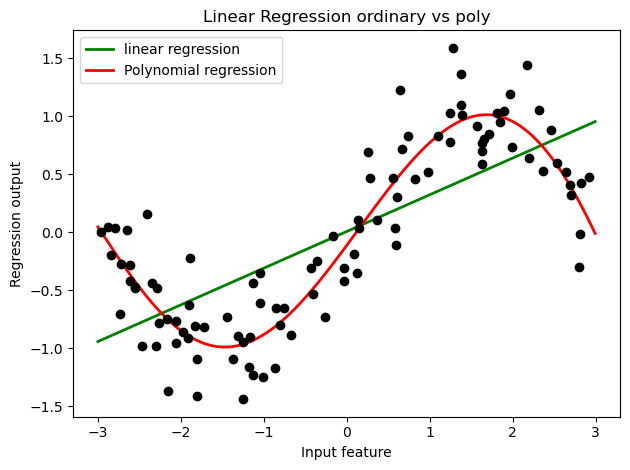

In [78]:
import matplotlib.pyplot as plt

d = 5
# 和上面展示一致的建模流程
LinearR = LinearRegression().fit(X, y) # 线性回归

X_ = PF(degree=d).fit_transform(X) # 多项式变换
LinearR_ = LinearRegression().fit(X_, y) # 多项式变换+线性回归训练模型

line = np.linspace(-3, 3, 1000, endpoint=False).reshape(-1, 1)
line_ = PF(degree=d).fit_transform(line) # 测试集数据多项式变换

# 放置画布
fig, ax1 = plt.subplots(1)

# 将测试数据带入predict接口，获得模型的拟合效果并进行绘制
ax1.plot(line, LinearR.predict(line), linewidth=2, color='green' # 未经过多项式变换+线性回归
         ,label="linear regression")
ax1.plot(line, LinearR_.predict(line_), linewidth=2, color='red' # 经过多项式变换+线性回归
         ,label="Polynomial regression")

# 将原数据上的拟合绘制在图像上
ax1.plot(X[:, 0], y, 'o', c='k')

# 其他图形选项
ax1.legend(loc="best")
ax1.set_ylabel("Regression output")
ax1.set_xlabel("Input feature")
ax1.set_title("Linear Regression ordinary vs poly")
plt.tight_layout()
plt.show()

# 感叹多项式回归的神奇

# 随后可以试试看较低和较高的次方会发生什么变化
# d = 2
# d = 20

In [79]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X = np.arange(9).reshape(3, 3)
X

array([[0, 1, 2],
       [3, 4, 5],
       [6, 7, 8]])

In [80]:
poly = PolynomialFeatures(degree=5).fit(X)

In [81]:
# 重要接口get_feature_names
poly.get_feature_names_out()

array(['1', 'x0', 'x1', 'x2', 'x0^2', 'x0 x1', 'x0 x2', 'x1^2', 'x1 x2',
       'x2^2', 'x0^3', 'x0^2 x1', 'x0^2 x2', 'x0 x1^2', 'x0 x1 x2',
       'x0 x2^2', 'x1^3', 'x1^2 x2', 'x1 x2^2', 'x2^3', 'x0^4', 'x0^3 x1',
       'x0^3 x2', 'x0^2 x1^2', 'x0^2 x1 x2', 'x0^2 x2^2', 'x0 x1^3',
       'x0 x1^2 x2', 'x0 x1 x2^2', 'x0 x2^3', 'x1^4', 'x1^3 x2',
       'x1^2 x2^2', 'x1 x2^3', 'x2^4', 'x0^5', 'x0^4 x1', 'x0^4 x2',
       'x0^3 x1^2', 'x0^3 x1 x2', 'x0^3 x2^2', 'x0^2 x1^3',
       'x0^2 x1^2 x2', 'x0^2 x1 x2^2', 'x0^2 x2^3', 'x0 x1^4',
       'x0 x1^3 x2', 'x0 x1^2 x2^2', 'x0 x1 x2^3', 'x0 x2^4', 'x1^5',
       'x1^4 x2', 'x1^3 x2^2', 'x1^2 x2^3', 'x1 x2^4', 'x2^5'],
      dtype=object)

In [82]:
from sklearn.datasets import fetch_california_housing as fch
import pandas as pd

housevalue = fch()
X = pd.DataFrame(housevalue.data)
y = housevalue.target
housevalue.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [83]:
X.columns = ["住户收入中位数","房屋使用年代中位数","平均房间数目"
            ,"平均卧室数目","街区人口","平均入住率","街区的纬度","街区的经度"]

In [84]:
X.head()

,住户收入中位数,房屋使用年代中位数,平均房间数目,平均卧室数目,街区人口,平均入住率,街区的纬度,街区的经度
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [85]:
poly = PolynomialFeatures(degree=4).fit(X, y)

In [86]:
poly.get_feature_names_out(X.columns)

array(['1', '住户收入中位数', '房屋使用年代中位数', '平均房间数目', '平均卧室数目', '街区人口', '平均入住率',
       '街区的纬度', '街区的经度', '住户收入中位数^2', '住户收入中位数 房屋使用年代中位数',
       '住户收入中位数 平均房间数目', '住户收入中位数 平均卧室数目', '住户收入中位数 街区人口',
       '住户收入中位数 平均入住率', '住户收入中位数 街区的纬度', '住户收入中位数 街区的经度', '房屋使用年代中位数^2',
       '房屋使用年代中位数 平均房间数目', '房屋使用年代中位数 平均卧室数目', '房屋使用年代中位数 街区人口',
       '房屋使用年代中位数 平均入住率', '房屋使用年代中位数 街区的纬度', '房屋使用年代中位数 街区的经度',
       '平均房间数目^2', '平均房间数目 平均卧室数目', '平均房间数目 街区人口', '平均房间数目 平均入住率',
       '平均房间数目 街区的纬度', '平均房间数目 街区的经度', '平均卧室数目^2', '平均卧室数目 街区人口',
       '平均卧室数目 平均入住率', '平均卧室数目 街区的纬度', '平均卧室数目 街区的经度', '街区人口^2',
       '街区人口 平均入住率', '街区人口 街区的纬度', '街区人口 街区的经度', '平均入住率^2', '平均入住率 街区的纬度',
       '平均入住率 街区的经度', '街区的纬度^2', '街区的纬度 街区的经度', '街区的经度^2', '住户收入中位数^3',
       '住户收入中位数^2 房屋使用年代中位数', '住户收入中位数^2 平均房间数目', '住户收入中位数^2 平均卧室数目',
       '住户收入中位数^2 街区人口', '住户收入中位数^2 平均入住率', '住户收入中位数^2 街区的纬度',
       '住户收入中位数^2 街区的经度', '住户收入中位数 房屋使用年代中位数^2',
       '住户收入中位数 房屋使用年代中位数 平均房间数目', '住户收入中位数 房屋使用年代中位数 平均卧室数目',
       '住户收入中位数 房

In [87]:
X_ = poly.transform(X)

In [89]:
# 在这之后，依然可以直接建立模型，然后使用线性回归的coef_属性来查看什么特征对标签的影响最大
reg = LinearRegression().fit(X_, y)

In [90]:
coef = reg.coef_

In [91]:
coef

array([ 3.10367273e-04, -2.23321368e-05, -1.60370263e-06, -7.05702252e-07,
       -1.28744969e-07, -5.24027314e-05,  1.47533419e-07,  3.99623947e-07,
        1.00952936e-08, -8.93911377e-06, -1.14115935e-05, -1.90793710e-05,
       -2.33593189e-06, -3.38803931e-05,  2.78374220e-06,  2.17959858e-08,
        7.01854660e-06, -2.10605244e-05,  8.54904116e-06, -6.97892921e-06,
       -7.61559801e-04,  3.50291974e-05,  4.55106175e-06,  5.36106141e-05,
       -1.14334807e-05,  3.61801302e-06, -1.33333692e-04, -4.76164598e-06,
        5.91163612e-07, -1.63319219e-06,  1.75605996e-06, -2.89884021e-05,
       -9.81404552e-07, -1.41203714e-06,  7.93330112e-06,  2.43737302e-05,
       -4.74375063e-05, -7.06805305e-04,  2.08497600e-03, -7.63212902e-06,
       -1.09719805e-06, -5.36883796e-06, -4.52046240e-06, -2.43013430e-05,
       -4.09161581e-06, -8.11446926e-05, -1.54852752e-04, -1.00421292e-04,
       -1.21307469e-05,  6.28884362e-04,  3.79857261e-05, -1.79545660e-04,
        5.50061871e-04, -

In [92]:
[*zip(poly.get_feature_names_out(X.columns), reg.coef_)]

[('1', 0.00031036727326845043),
 ('住户收入中位数', -2.2332136833629594e-05),
 ('房屋使用年代中位数', -1.6037026260058903e-06),
 ('平均房间数目', -7.057022521705797e-07),
 ('平均卧室数目', -1.2874496874042413e-07),
 ('街区人口', -5.240273141627593e-05),
 ('平均入住率', 1.475334189942723e-07),
 ('街区的纬度', 3.996239473718978e-07),
 ('街区的经度', 1.009529362997888e-08),
 ('住户收入中位数^2', -8.939113770126871e-06),
 ('住户收入中位数 房屋使用年代中位数', -1.1411593510581003e-05),
 ('住户收入中位数 平均房间数目', -1.90793710475929e-05),
 ('住户收入中位数 平均卧室数目', -2.335931892703171e-06),
 ('住户收入中位数 街区人口', -3.3880393080916464e-05),
 ('住户收入中位数 平均入住率', 2.7837422037157124e-06),
 ('住户收入中位数 街区的纬度', 2.1795985785587715e-08),
 ('住户收入中位数 街区的经度', 7.018546597640368e-06),
 ('房屋使用年代中位数^2', -2.1060524448791983e-05),
 ('房屋使用年代中位数 平均房间数目', 8.549041162167556e-06),
 ('房屋使用年代中位数 平均卧室数目', -6.978929206661385e-06),
 ('房屋使用年代中位数 街区人口', -0.0007615598013116882),
 ('房屋使用年代中位数 平均入住率', 3.502919744337384e-05),
 ('房屋使用年代中位数 街区的纬度', 4.551061746558552e-06),
 ('房屋使用年代中位数 街区的经度', 5.3610614134750165e-05),
 ('

In [93]:
#放到dataframe中进行排序
coeff = pd.DataFrame([poly.get_feature_names_out(X.columns), reg.coef_.tolist()]).T

In [94]:
coeff.head()

,0,1
0,1,0.00031
1,住户收入中位数,-0.000022
2,房屋使用年代中位数,-0.000002
3,平均房间数目,-0.000001
4,平均卧室数目,-0.0


In [95]:
coeff.columns = ["feature","coef"]

In [96]:
coeff.sort_values(by="coef")

,feature,coef
491,街区的纬度^3 街区的经度,-0.010765
490,街区的纬度^4,-0.008709
492,街区的纬度^2 街区的经度^2,-0.004984
377,平均房间数目^2 平均卧室数目 平均入住率,-0.00375
421,平均房间数目 街区的纬度^3,-0.002568
...,...,...
38,街区人口 街区的经度,0.002085
183,住户收入中位数^2 平均房间数目 平均入住率,0.002111
319,房屋使用年代中位数 平均房间数目 平均卧室数目^2,0.002463
168,住户收入中位数^3 平均卧室数目,0.002861


In [97]:
# 顺便看一下多项式变化之后，模型的拟合效果如何
poly = PolynomialFeatures(degree=4).fit(X,y)
X_ = poly.transform(X)

In [98]:
# 原始的线性回归结果
reg = LinearRegression().fit(X,y)
reg.score(X,y)

0.606232685199805

In [106]:
from time import time
time0 = time()
reg_ = LinearRegression().fit(X_,y)
print("R2:{}".format(reg_.score(X_,y)))
print("time:{}".format(time()-time0))

R2:0.7451024403114478
time:3.0221009254455566


In [105]:
# 假设使用其他模型——随机森林回归器
from sklearn.ensemble import RandomForestRegressor as RFR

time0 = time()
print("R2:{}".format(RFR(n_estimators=100).fit(X,y).score(X,y)))
print("time:{}".format(time()-time0))

R2:0.9739897331343784
time:11.671009063720703
